# Experiment 035: matched GRPO at 1.5B and 3B

Matched LoRA and full parameter runs at 1.5B and 3B. It uses the committed W&B exports for the first 50 updates comparison and the archived endpoint files for accuracy!

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, mcnemar_exact, paired_delta_ci

RES = ROOT / 'results'
TECH = RES / '035_technical'
FIG = ROOT / 'analysis' / 'figures' / '035_7'
FIG.mkdir(parents=True, exist_ok=True)


def jload(path):
    with open(path) as handle:
        return json.load(handle)


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def accuracy(rows):
    return float(np.mean([row['correct'] for row in rows]))


def add_overall(metrics, rows):
    metrics = dict(metrics)
    metrics['overall'] = accuracy(rows)
    return metrics


def grouped_accuracy(metrics):
    return np.array([
        metrics['overall'],
        metrics['per_tier_acc']['easy'],
        metrics['per_tier_acc']['medium'],
        metrics['per_tier_acc']['hard'],
    ]) * 100


def load_eval(result_dir, metrics_name, rows_name):
    rows = read_jsonl(result_dir / rows_name)
    return add_overall(jload(result_dir / metrics_name), rows), rows


def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')


paths = {
    '3B': {
        'start': RES / '035_start_B3_seed0',
        'historical': RES / '003_COLAB_FULL_B3_sft_grpo_seed0',
        'lora': RES / '035_COLAB_FULL_B3_matched_lora_grpo_seed0',
        'full': RES / '035_COLAB_FULL_B3_matched_full_grpo_seed0',
    },
    '1.5B': {
        'start': RES / '035b_start_B15_seed0',
        'historical': RES / '009_COLAB_FULL_B15_sft_grpo_seed0',
        'lora': RES / '035_COLAB_FULL_B15_matched_lora_grpo_seed0',
        'full': RES / '035_COLAB_FULL_B15_matched_full_grpo_seed0',
    },
}

data = {}
for scale, scale_paths in paths.items():
    start_probe, start_rows = load_eval(scale_paths['start'], 'start_logprob.json', 'start_logprob_preds.jsonl')
    hist_probe, hist_probe_rows = load_eval(scale_paths['historical'], 'grpo_logprob.json', 'grpo_logprob_preds.jsonl')
    hist_gen, hist_gen_rows = load_eval(scale_paths['historical'], 'grpo_eval.json', 'grpo_preds.jsonl')
    lora_probe, lora_probe_rows = load_eval(scale_paths['lora'], 'grpo_logprob.json', 'grpo_logprob_preds.jsonl')
    lora_gen, lora_gen_rows = load_eval(scale_paths['lora'], 'grpo_eval.json', 'grpo_preds.jsonl')
    data[scale] = {
        'start_probe': start_probe,
        'start_rows': start_rows,
        'hist_probe': hist_probe,
        'hist_probe_rows': hist_probe_rows,
        'hist_gen': hist_gen,
        'hist_gen_rows': hist_gen_rows,
        'lora_probe': lora_probe,
        'lora_probe_rows': lora_probe_rows,
        'lora_gen': lora_gen,
        'lora_gen_rows': lora_gen_rows,
    }
    if scale == '1.5B':
        full_probe, full_probe_rows = load_eval(scale_paths['full'], 'grpo_logprob.json', 'grpo_logprob_preds.jsonl')
        full_gen, full_gen_rows = load_eval(scale_paths['full'], 'grpo_eval.json', 'grpo_preds.jsonl')
        data[scale].update({
            'full_probe': full_probe,
            'full_probe_rows': full_probe_rows,
            'full_gen': full_gen,
            'full_gen_rows': full_gen_rows,
        })

history_manifest = jload(TECH / '035b_q3_wandb_history_manifest.json')
full_histories = {}
for record in history_manifest['records']:
    history_path = TECH / Path(record['history_path']).name
    assert file_sha256(history_path) == record['history_sha256']
    history = pd.DataFrame(read_jsonl(history_path)).sort_values('step')
    assert history['step'].tolist()[:50] == list(range(1, 51))
    assert len(history) == record['row_count']
    full_histories[record['scale']] = history

lora_logs = {
    '3B': pd.DataFrame(jload(paths['3B']['lora'] / 'grpo_trainlog.json')),
    '1.5B': pd.DataFrame(jload(paths['1.5B']['lora'] / 'grpo_trainlog.json')),
}
full_b15_log = pd.DataFrame(jload(paths['1.5B']['full'] / 'grpo_trainlog.json'))
for frame in [*lora_logs.values(), full_b15_log]:
    frame.dropna(subset=['step', 'reward'], inplace=True)

plt.style.use('seaborn-v0_8-whitegrid')
print('figures ->', FIG.relative_to(ROOT))


figures -> analysis/figures/035_7


## Training outcomes

,scale,mode,outcome,updates,peak_reserved_gib
0,3B,Full,A1 stop,50,67.21
1,3B,LoRA,Completed,500,24.12
2,1.5B,Full,Completed,500,38.26
3,1.5B,LoRA,Completed,500,17.45


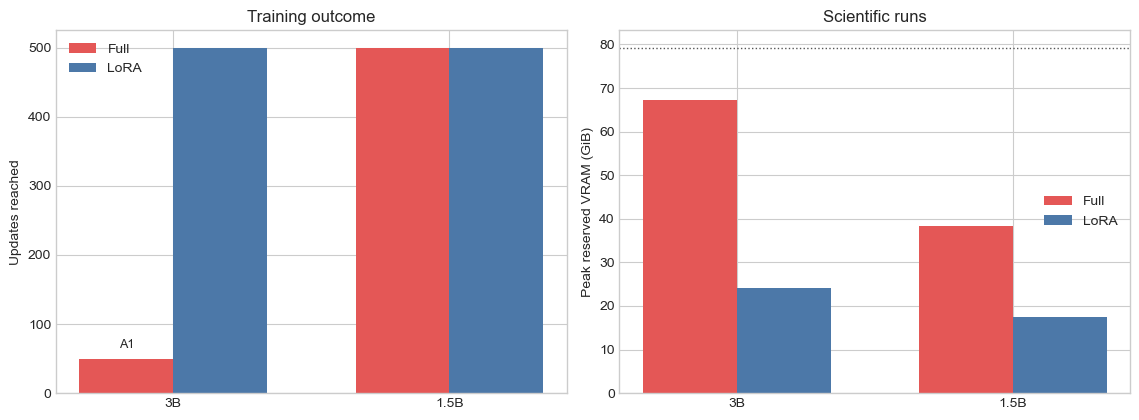

In [2]:
status = {
    (scale, mode): jload(paths[scale][mode] / 'worker_status.json')
    for scale in ('3B', '1.5B')
    for mode in ('full', 'lora')
}

lora_b15_attempts = read_jsonl(paths['1.5B']['lora'] / '035b_attempts.jsonl')
outcomes = pd.DataFrame([
    {'scale': '3B', 'mode': 'Full', 'outcome': 'A1 stop', 'updates': 50,
     'peak_reserved_gib': status['3B', 'full']['peak_reserved_gib']},
    {'scale': '3B', 'mode': 'LoRA', 'outcome': 'Completed', 'updates': 500,
     'peak_reserved_gib': status['3B', 'lora']['peak_reserved_gib']},
    {'scale': '1.5B', 'mode': 'Full', 'outcome': 'Completed', 'updates': 500,
     'peak_reserved_gib': status['1.5B', 'full']['peak_reserved_gib']},
    {'scale': '1.5B', 'mode': 'LoRA', 'outcome': 'Completed', 'updates': 500,
     'peak_reserved_gib': max(row.get('peak_reserved_gib', 0) for row in lora_b15_attempts)},
])
display(outcomes)

x = np.arange(2)
width = 0.34
full_rows = outcomes[outcomes['mode'] == 'Full'].set_index('scale').loc[['3B', '1.5B']]
lora_rows = outcomes[outcomes['mode'] == 'LoRA'].set_index('scale').loc[['3B', '1.5B']]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].bar(x - width / 2, full_rows['updates'], width, label='Full', color='#E45756')
axes[0].bar(x + width / 2, lora_rows['updates'], width, label='LoRA', color='#4C78A8')
axes[0].text(x[0] - width / 2, 65, 'A1', ha='center', fontsize=9)
axes[0].set_xticks(x, ['3B', '1.5B'])
axes[0].set_ylabel('Updates reached')
axes[0].set_title('Training outcome')
axes[0].legend()

axes[1].bar(x - width / 2, full_rows['peak_reserved_gib'], width, label='Full', color='#E45756')
axes[1].bar(x + width / 2, lora_rows['peak_reserved_gib'], width, label='LoRA', color='#4C78A8')
axes[1].axhline(79.25, color='#555555', linestyle=':', linewidth=1)
axes[1].set_xticks(x, ['3B', '1.5B'])
axes[1].set_ylabel('Peak reserved VRAM (GiB)')
axes[1].set_title('Scientific runs')
axes[1].legend()

fig.tight_layout()
save(fig, 'training_outcomes')
plt.show()


## Full-parameter behaviour in the first 50 updates

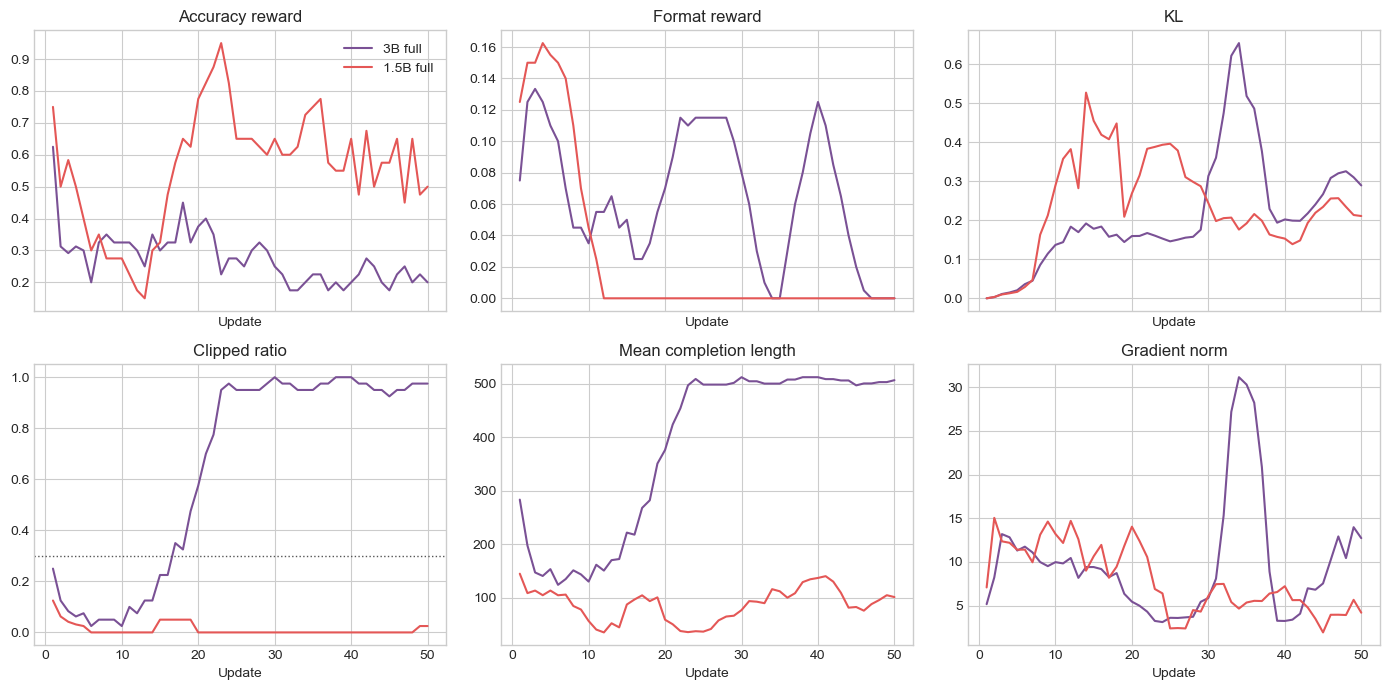

,Accuracy reward,Format reward,KL,Clipped ratio,Mean completion length,Gradient norm,Reward spread,Zero reward spread
scale,,,,,,,,
3B,0.2625,0.0605,0.2232,0.67,390.5900,9.9501,0.4082,0.08
1.5B,0.5550,0.0200,0.2460,0.01,85.9775,7.6543,0.2682,0.38


In [3]:
q3_series = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('kl', 'KL'),
    ('completions/clipped_ratio', 'Clipped ratio'),
    ('completions/mean_length', 'Mean completion length'),
    ('grad_norm', 'Gradient norm'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, q3_series):
    for scale, color in [('B3', '#7A5195'), ('B15', '#E45756')]:
        frame = full_histories[scale].head(50)
        label = '3B full' if scale == 'B3' else '1.5B full'
        ax.plot(frame['step'], frame[column].rolling(5, min_periods=1).mean(),
                label=label, color=color)
    if column == 'completions/clipped_ratio':
        ax.axhline(0.30, color='#555555', linestyle=':', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel('Update')
axes[0, 0].legend()
fig.tight_layout()
save(fig, 'full_first_50')
plt.show()

q3_means = []
for scale, frame in full_histories.items():
    row = {'scale': {'B3': '3B', 'B15': '1.5B'}[scale]}
    for column, title in q3_series:
        row[title] = frame.head(50)[column].mean()
    row['Reward spread'] = frame.head(50)['reward_std'].mean()
    row['Zero reward spread'] = frame.head(50)['frac_reward_zero_std'].mean()
    q3_means.append(row)
q3_table = pd.DataFrame(q3_means).set_index('scale').loc[['3B', '1.5B']]
display(q3_table.round(4))


## Endpoint comparison

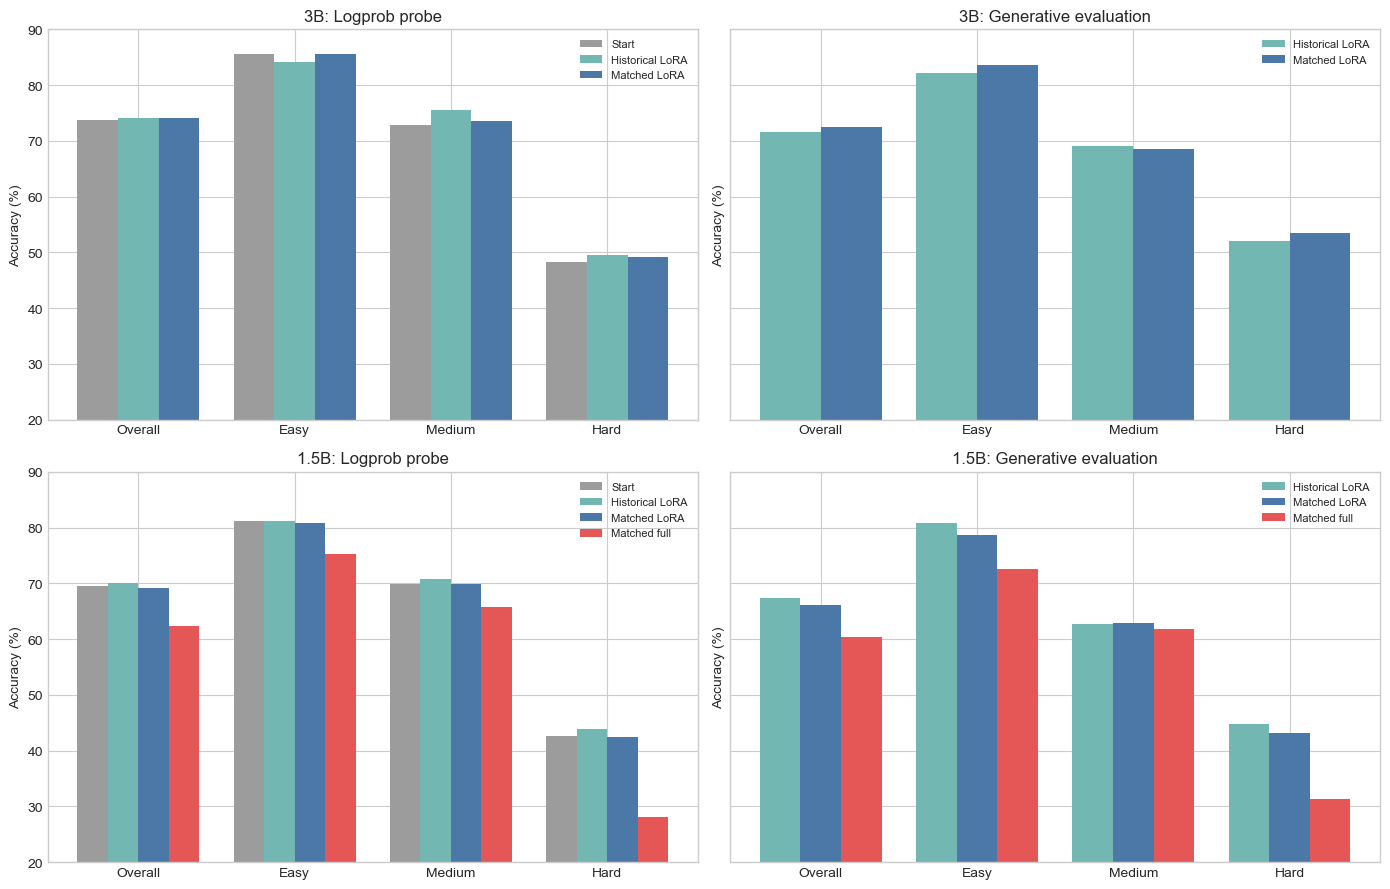

In [4]:
groups = ['Overall', 'Easy', 'Medium', 'Hard']
series_colors = {
    'Start': '#9C9C9C',
    'Historical LoRA': '#72B7B2',
    'Matched LoRA': '#4C78A8',
    'Matched full': '#E45756',
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for row_index, scale in enumerate(('3B', '1.5B')):
    panels = [
        ('Logprob probe', [
            ('Start', data[scale]['start_probe']),
            ('Historical LoRA', data[scale]['hist_probe']),
            ('Matched LoRA', data[scale]['lora_probe']),
            *(([('Matched full', data[scale]['full_probe'])]) if scale == '1.5B' else []),
        ]),
        ('Generative evaluation', [
            ('Historical LoRA', data[scale]['hist_gen']),
            ('Matched LoRA', data[scale]['lora_gen']),
            *(([('Matched full', data[scale]['full_gen'])]) if scale == '1.5B' else []),
        ]),
    ]
    for col_index, (title, panel_series) in enumerate(panels):
        ax = axes[row_index, col_index]
        x = np.arange(len(groups))
        width = 0.78 / len(panel_series)
        offsets = (np.arange(len(panel_series)) - (len(panel_series) - 1) / 2) * width
        for offset, (label, metrics) in zip(offsets, panel_series):
            ax.bar(x + offset, grouped_accuracy(metrics), width, label=label,
                   color=series_colors[label])
        ax.set_xticks(x, groups)
        ax.set_title(f'{scale}: {title}')
        ax.set_ylabel('Accuracy (%)')
        ax.set_ylim(20, 90)
        ax.legend(fontsize=8)

fig.tight_layout()
save(fig, 'endpoint_tiers_by_scale')
plt.show()


## Completed training trajectories

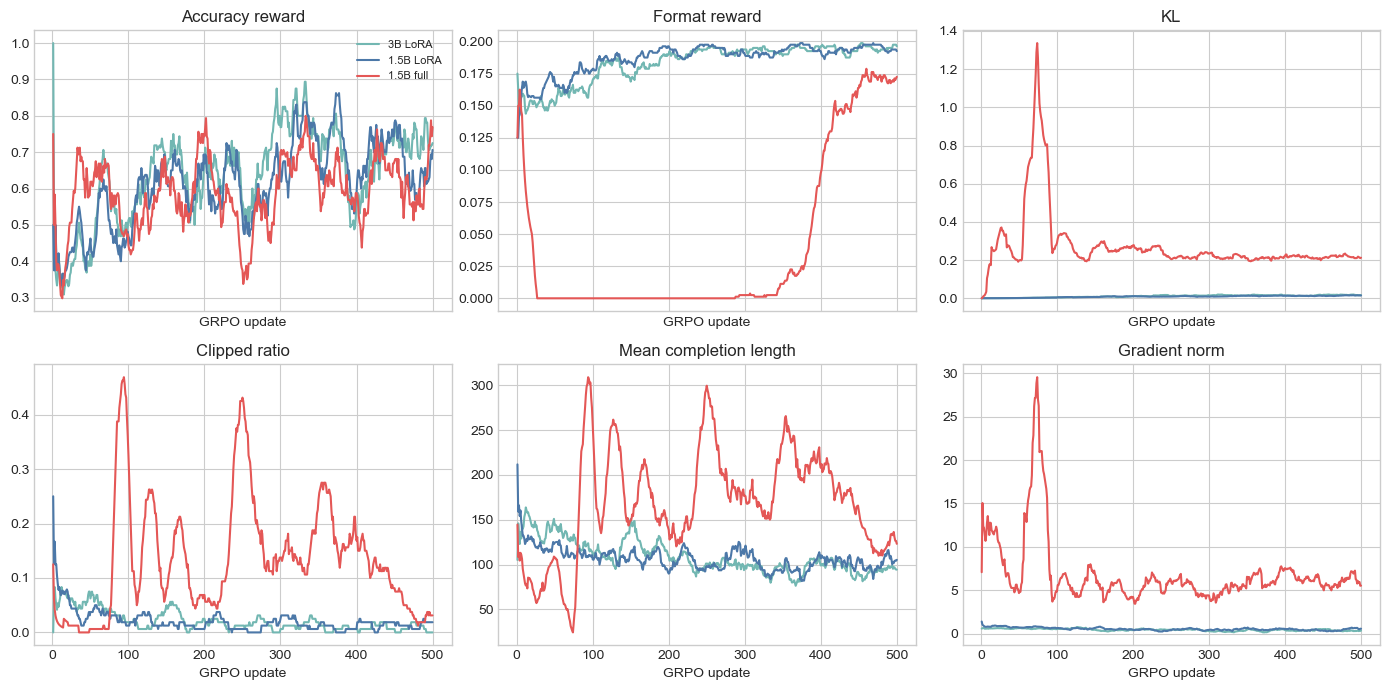

In [5]:
training_series = [
    ('rewards/accuracy_reward/mean', 'Accuracy reward'),
    ('rewards/format_reward/mean', 'Format reward'),
    ('kl', 'KL'),
    ('completions/clipped_ratio', 'Clipped ratio'),
    ('completions/mean_length', 'Mean completion length'),
    ('grad_norm', 'Gradient norm'),
]
completed_logs = [
    ('3B LoRA', lora_logs['3B'], '#72B7B2'),
    ('1.5B LoRA', lora_logs['1.5B'], '#4C78A8'),
    ('1.5B full', full_b15_log, '#E45756'),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, (column, title) in zip(axes.flat, training_series):
    for label, frame, color in completed_logs:
        ax.plot(frame['step'], frame[column].rolling(20, min_periods=1).mean(),
                label=label, color=color)
    ax.set_title(title)
    ax.set_xlabel('GRPO update')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
save(fig, 'completed_training_dynamics')
plt.show()


## Exact values

In [6]:
def paired_stats(rows_a, rows_b):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    correct_a = np.array([row['correct'] for row in rows_a], dtype=bool)
    correct_b = np.array([row['correct'] for row in rows_b], dtype=bool)
    gains = int(np.sum(~correct_a & correct_b))
    losses = int(np.sum(correct_a & ~correct_b))
    delta, low, high = paired_delta_ci(correct_a, correct_b, n_boot=10000, seed=35)
    return {
        'delta_pp': 100 * delta,
        'ci_low_pp': 100 * low,
        'ci_high_pp': 100 * high,
        'gains': gains,
        'losses': losses,
        'mcnemar_p': mcnemar_exact(gains, losses),
    }


endpoint_rows = []
for scale in ('3B', '1.5B'):
    endpoint_rows.extend([
        {'scale': scale, 'result': 'Start probe', 'accuracy': 100 * data[scale]['start_probe']['overall']},
        {'scale': scale, 'result': 'Historical LoRA probe', 'accuracy': 100 * data[scale]['hist_probe']['overall']},
        {'scale': scale, 'result': 'Matched LoRA probe', 'accuracy': 100 * data[scale]['lora_probe']['overall']},
        {'scale': scale, 'result': 'Historical LoRA generative', 'accuracy': 100 * data[scale]['hist_gen']['overall']},
        {'scale': scale, 'result': 'Matched LoRA generative', 'accuracy': 100 * data[scale]['lora_gen']['overall']},
    ])
endpoint_rows.extend([
    {'scale': '1.5B', 'result': 'Matched full probe', 'accuracy': 100 * data['1.5B']['full_probe']['overall']},
    {'scale': '1.5B', 'result': 'Matched full generative', 'accuracy': 100 * data['1.5B']['full_gen']['overall']},
])
endpoint_table = pd.DataFrame(endpoint_rows)

paired_table = pd.DataFrame([
    {'comparison': '3B start to matched LoRA probe',
     **paired_stats(data['3B']['start_rows'], data['3B']['lora_probe_rows'])},
    {'comparison': '3B historical to matched LoRA probe',
     **paired_stats(data['3B']['hist_probe_rows'], data['3B']['lora_probe_rows'])},
    {'comparison': '1.5B start to matched full probe',
     **paired_stats(data['1.5B']['start_rows'], data['1.5B']['full_probe_rows'])},
    {'comparison': '1.5B start to matched LoRA probe',
     **paired_stats(data['1.5B']['start_rows'], data['1.5B']['lora_probe_rows'])},
    {'comparison': '1.5B full to matched LoRA probe',
     **paired_stats(data['1.5B']['full_probe_rows'], data['1.5B']['lora_probe_rows'])},
    {'comparison': '1.5B historical to matched LoRA probe',
     **paired_stats(data['1.5B']['hist_probe_rows'], data['1.5B']['lora_probe_rows'])},
])

training_means = []
for label, frame, _ in completed_logs:
    training_means.append({
        'run': label,
        'accuracy_reward': frame['rewards/accuracy_reward/mean'].mean(),
        'format_reward': frame['rewards/format_reward/mean'].mean(),
        'kl': frame['kl'].mean(),
        'mean_length': frame['completions/mean_length'].mean(),
        'clipped_ratio': frame['completions/clipped_ratio'].mean(),
        'grad_norm': frame['grad_norm'].mean(),
    })

display(endpoint_table.round(3))
display(paired_table.round(4))
display(q3_table.round(4))
display(pd.DataFrame(training_means).round(4))


,scale,result,accuracy
0,3B,Start probe,73.673
1,3B,Historical LoRA probe,74.098
2,3B,Matched LoRA probe,74.098
3,3B,Historical LoRA generative,71.603
4,3B,Matched LoRA generative,72.399
5,1.5B,Start probe,69.480
6,1.5B,Historical LoRA probe,70.011
7,1.5B,Matched LoRA probe,69.214
8,1.5B,Historical LoRA generative,67.410
9,1.5B,Matched LoRA generative,66.083


,comparison,delta_pp,ci_low_pp,ci_high_pp,gains,losses,mcnemar_p
0,3B start to matched LoRA probe,0.4246,-0.0531,0.9023,15,7,0.1338
1,3B historical to matched LoRA probe,0.0000,-0.4777,0.4777,11,11,1.0000
2,1.5B start to matched full probe,-7.1656,-9.2357,-5.0955,129,264,0.0000
3,1.5B start to matched LoRA probe,-0.2654,-0.8493,0.3185,14,19,0.4869
4,1.5B full to matched LoRA probe,6.9002,4.8832,8.9172,255,125,0.0000
5,1.5B historical to matched LoRA probe,-0.7962,-1.4331,-0.2123,10,25,0.0167


,Accuracy reward,Format reward,KL,Clipped ratio,Mean completion length,Gradient norm,Reward spread,Zero reward spread
scale,,,,,,,,
3B,0.2625,0.0605,0.2232,0.67,390.5900,9.9501,0.4082,0.08
1.5B,0.5550,0.0200,0.2460,0.01,85.9775,7.6543,0.2682,0.38


,run,accuracy_reward,format_reward,kl,mean_length,clipped_ratio,grad_norm
0,3B LoRA,0.6450,0.1841,0.0115,107.7285,0.0202,0.4477
1,1.5B LoRA,0.6202,0.1875,0.0092,105.6602,0.0185,0.5515
2,1.5B full,0.5952,0.0409,0.2778,169.2775,0.1340,6.7971


## Cross-referenced conclusion

The 3B full arm reached A1 at update 50, while the 1.5B full arm completed, and viability differed across the two scale bundles. The first 50 histories show that 3B was dominated by long clipped completions, while 1.5B stayed quite short to continue. Completion wasnt accuracy success at 1.5B. Full fell 7.17 probe points from the shared start and finished 6.90 points below matched LoRA. Together the two experiments support a stabilising role for LoRA under this recipe, but they do not establish a causal scale effect or a multi-seed result.